# EDA — Home Credit Default Risk (`application_train`)

**Objetivo:** entender os dados, identificar problemas de qualidade e descobrir quais variáveis têm mais poder de explicação sobre o `TARGET` (1 = cliente com dificuldade de pagamento).

**Roteiro**
1. Setup e carga
2. Visão geral e qualidade dos dados
3. Análise do target
4. Valores faltantes
5. Anomalias e limpeza leve
6. Análise univariada
7. Análise bivariada (variável × target)
8. Correlações
9. Poder explicativo: métodos univariados (AUC, KS, IV, informação mútua, Cramér's V)
10. Poder explicativo: métodos baseados em modelo (LightGBM, permutation importance, SHAP)
11. Ranking consolidado
12. Teste rápido de features engenheiradas
13. Conclusões e próximos passos

> **Dados:** baixe `application_train.csv` (e, opcionalmente, `application_test.csv`) da página da competição e coloque em `../data/raw/`.

## 1. Setup e carga

In [3]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
from configs.paths import APPLICATION_TRAIN

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ks_2samp
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
TARGET, ID = "TARGET", "SK_ID_CURR"

# Controle de custo computacional
RUN_MODEL = True      # False pula a seção 10 (LightGBM/SHAP)
N_SPLITS = 5

In [4]:
df = pd.read_csv(APPLICATION_TRAIN)
print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")
df.head()

Linhas: 307,511 | Colunas: 122


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.0000","406,597.5000","24,700.5000","351,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,"-3,648.0000",-2120,NaN,1,1,0,1,1,0,Laborers,1.0000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.0830,0.2629,0.1394,0.0247,0.0369,0.9722,0.6192,0.0143,0.0000,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.0220,0.0198,0.0000,0.0000,0.0250,0.0369,0.9722,0.6243,0.0144,0.0000,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.0000,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0000,2.0000,2.0000,2.0000,"-1,134.0000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1,100003,0,Cash loans,F,N,N,0,"270,000.0000","1,293,502.5000","35,698.5000","1,129,500.0000",Family,State servant,Higher education,Married,House / apartment,0.0035,-16765,-1188,"-1,186.0000",-291,NaN,1,1,0,1,1,0,Core staff,2.0000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.3113,0.6222,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.0800,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.0790,0.0554,0.0000,0.0000,0.0968,0.0529,0.9851,0.7987,0.0608,0.0800,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.0100,reg oper account,block of flats,0.0714,Block,No,1.0000,0.0000,1.0000,0.0000,-828.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.0000","135,000.0000","6,750.0000","135,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0100,-19046,-225,"-4,260.0000",-2531,26.0000,1,1,1,1,1,0,Laborers,1.0000

In [5]:
def grid(n, ncols=3, h=4):
    """Cria uma grade de eixos e desliga os que sobrarem."""
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, h * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    return fig, axes

## 2. Visão geral e qualidade dos dados

**O que observar:** tipos das colunas (algum numérico que deveria ser categórico? datas?), memória, chave única, duplicatas.

In [6]:
print("Tipos de dados:")
print(df.dtypes.value_counts().to_string(), "\n")
print(f"Memória: {df.memory_usage(deep=True).sum() / 1e6:,.1f} MB")
print(f"{ID} único? {df[ID].is_unique}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")

Tipos de dados:
float64    65
int64      41
str        16 

Memória: 529.5 MB
SK_ID_CURR único? True
Linhas duplicadas: 0


In [7]:
df.describe().T.head(40)

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,"307,511.0000","278,180.5186","102,790.1753","100,002.0000","189,145.5000","278,202.0000","367,142.5000","456,255.0000"
TARGET,"307,511.0000",0.0807,0.2724,0.0000,0.0000,0.0000,0.0000,1.0000
CNT_CHILDREN,"307,511.0000",0.4171,0.7221,0.0000,0.0000,0.0000,1.0000,19.0000
AMT_INCOME_TOTAL,"307,511.0000","168,797.9193","237,123.1463","25,650.0000","112,500.0000","147,150.0000","202,500.0000","117,000,000.0000"
AMT_CREDIT,"307,511.0000","599,025.9997","402,490.7770","45,000.0000","270,000.0000","513,531.0000","808,650.0000","4,050,000.0000"
AMT_ANNUITY,"307,499.0000","27,108.5739","14,493.7373","1,615.5000","16,524.0000","24,903.0000","34,596.0000","258,025.5000"
AMT_GOODS_PRICE,"307,233.0000","538,396.2074","369,446.4605","40,500.0000","238,500.0000","450,000.0000","679,500.0000","4,050,000.0000"
REGION_POPULATION_RELATIVE,"307,511.0000",0.0209,0.0138,0.0003,0.0100,0.0188,0.0287,0.0725
DAYS_BIRTH,"307,511.0000","-16,036.9951","4,363.9886","-25,229.0000","-19,682.0000","-15,750.0000","-12,413.0000","-7,489.0000"
DAYS_EMPLOYED,"307,511.0000","63,815.0459","141,275.7665","-17,912.0000","-2,760.0000","-1,213.0000",-289.0000,"365,243.0000"


## 3. Análise do target

**O que observar:** taxa de evento. Uma classe rara (~8%) pede **validação estratificada** e uma métrica robusta a desbalanceamento (AUC), e não acurácia: um modelo que prevê "ninguém é inadimplente" acerta ~92%.

TARGET
0    282686
1     24825

Taxa de inadimplência: 8.07%
Razão não-evento : evento = 11.4 : 1


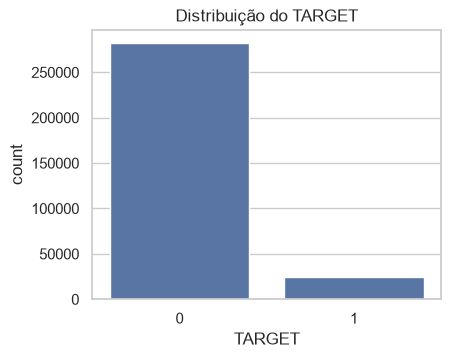

In [8]:
vc = df[TARGET].value_counts()
print(vc.to_string())
print(f"\nTaxa de inadimplência: {df[TARGET].mean():.2%}")
print(f"Razão não-evento : evento = {vc[0] / vc[1]:.1f} : 1")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(x=TARGET, data=df, ax=ax)
ax.set_title("Distribuição do TARGET")
plt.show()

## 4. Valores faltantes

**O que observar:**
- Quais colunas têm muitos nulos? (em Home Credit, o bloco de moradia `*_AVG/_MODE/_MEDI` passa de 50%)
- A **ausência é informativa?** Se a taxa de inadimplência difere entre quem tem e quem não tem o valor, o próprio nulo é um sinal (e vale criar um indicador de ausência).

67 colunas com nulos | 41 com mais de 50% de nulos


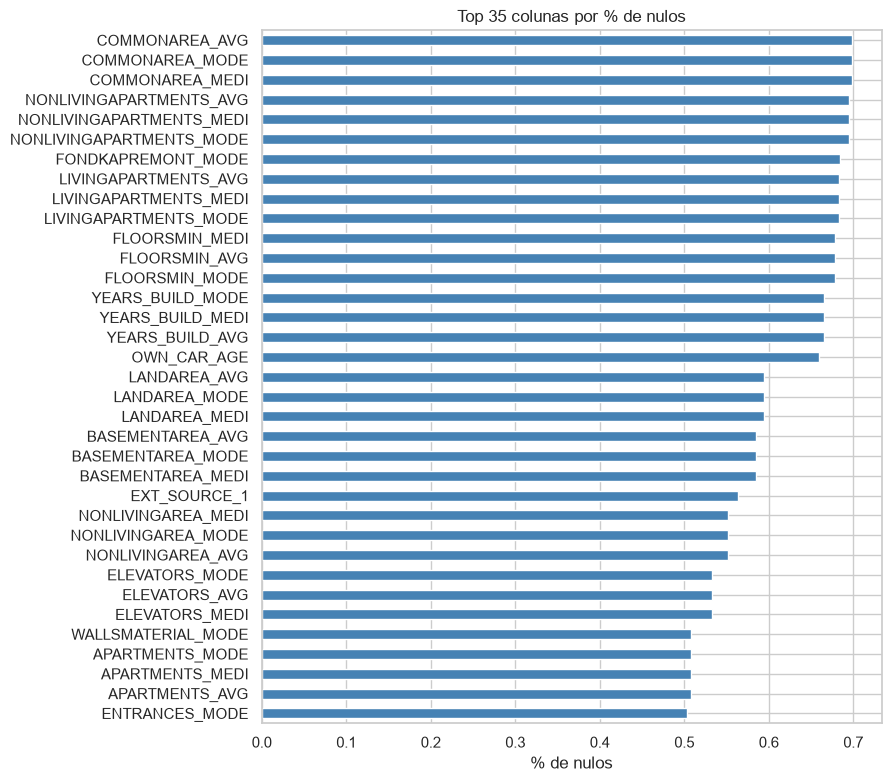

In [9]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print(f"{len(miss)} colunas com nulos | {(miss > 0.5).sum()} com mais de 50% de nulos")

fig, ax = plt.subplots(figsize=(8, 9))
miss.head(35).sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title("Top 35 colunas por % de nulos")
ax.set_xlabel("% de nulos")
plt.show()

In [10]:
rows = []
for c in miss.index:
    m = df[c].isna()
    if m.sum() >= 200 and (~m).sum() >= 200:
        rows.append({
            "coluna": c,
            "pct_nulos": m.mean(),
            "default_se_nulo": df.loc[m, TARGET].mean(),
            "default_se_preenchido": df.loc[~m, TARGET].mean(),
        })
miss_tgt = pd.DataFrame(rows)
miss_tgt["delta"] = miss_tgt["default_se_nulo"] - miss_tgt["default_se_preenchido"]
miss_tgt.reindex(miss_tgt["delta"].abs().sort_values(ascending=False).index).head(15).reset_index(drop=True)

,coluna,pct_nulos,default_se_nulo,default_se_preenchido,delta
0,DEF_30_CNT_SOCIAL_CIRCLE,0.0033,0.0353,0.0809,-0.0456
1,OBS_30_CNT_SOCIAL_CIRCLE,0.0033,0.0353,0.0809,-0.0456
2,DEF_60_CNT_SOCIAL_CIRCLE,0.0033,0.0353,0.0809,-0.0456
3,OBS_60_CNT_SOCIAL_CIRCLE,0.0033,0.0353,0.0809,-0.0456
4,NAME_TYPE_SUITE,0.0042,0.0542,0.0808,-0.0267
5,AMT_REQ_CREDIT_BUREAU_MON,0.1350,0.1034,0.0772,0.0262
6,AMT_REQ_CREDIT_BUREAU_YEAR,0.1350,0.1034,0.0772,0.0262
7,AMT_REQ_CREDIT_BUREAU_HOUR,0.1350,0.1034,0.0772,0.0262
8,AMT_REQ_CREDIT_BUREAU_DAY,0.1350,0.1034,0.0772,0.0262
9,AMT_REQ_CREDIT_BUREAU_WEEK,0.1350,0.1034,0.0772,0.0262


## 5. Anomalias e limpeza leve

Achados conhecidos neste dataset:
- `DAYS_EMPLOYED = 365243` é um **valor sentinela** (~1.000 anos!) usado para aposentados/desempregados.
- `XNA` em `CODE_GENDER` / `ORGANIZATION_TYPE` significa "não informado".
- As colunas `DAYS_*` são negativas (dias antes do pedido); convertemos para anos para facilitar a leitura.

Criamos uma cópia de trabalho `d` e preservamos `df` como o dado original.

In [11]:
print("DAYS_EMPLOYED:")
print(df["DAYS_EMPLOYED"].describe().to_string())
anom = df["DAYS_EMPLOYED"] == 365243
print(f"\nSentinela 365243: {anom.sum():,} linhas ({anom.mean():.1%})")
print("\nTaxa de default por grupo:")
print(df.groupby(anom)[TARGET].mean().rename({False: "valor normal", True: "sentinela"}).to_string())

DAYS_EMPLOYED:
count   307,511.0000
mean     63,815.0459
std     141,275.7665
min     -17,912.0000
25%      -2,760.0000
50%      -1,213.0000
75%        -289.0000
max     365,243.0000

Sentinela 365243: 55,374 linhas (18.0%)

Taxa de default por grupo:
DAYS_EMPLOYED
valor normal   0.0866
sentinela      0.0540


In [12]:
d = df.copy()

# Sentinela -> NaN, mas preservando a informação em um indicador
d["DAYS_EMPLOYED_ANOM"] = (d["DAYS_EMPLOYED"] == 365243).astype(int)
d["DAYS_EMPLOYED"] = d["DAYS_EMPLOYED"].replace(365243, np.nan)

# "XNA" -> NaN
for c in ["CODE_GENDER", "ORGANIZATION_TYPE"]:
    if c in d.columns:
        d[c] = d[c].replace("XNA", np.nan)

# Dias -> anos (valores positivos)
d["AGE_YEARS"] = -d["DAYS_BIRTH"] / 365.25
d["YEARS_EMPLOYED"] = -d["DAYS_EMPLOYED"] / 365.25

cat_cols = d.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in d.select_dtypes(include="number").columns
            if c not in (TARGET, ID) and d[c].notna().any()]

# Amostra para etapas custosas (correlações, gráficos de densidade)
d_s = d.sample(min(len(d), 100_000), random_state=SEED)

print(f"{len(num_cols)} colunas numéricas | {len(cat_cols)} categóricas")

107 colunas numéricas | 16 categóricas


## 6. Análise univariada

**O que observar:** assimetria (caudas longas pedem log ou *clipping*), outliers, categorias raras e cardinalidade alta.

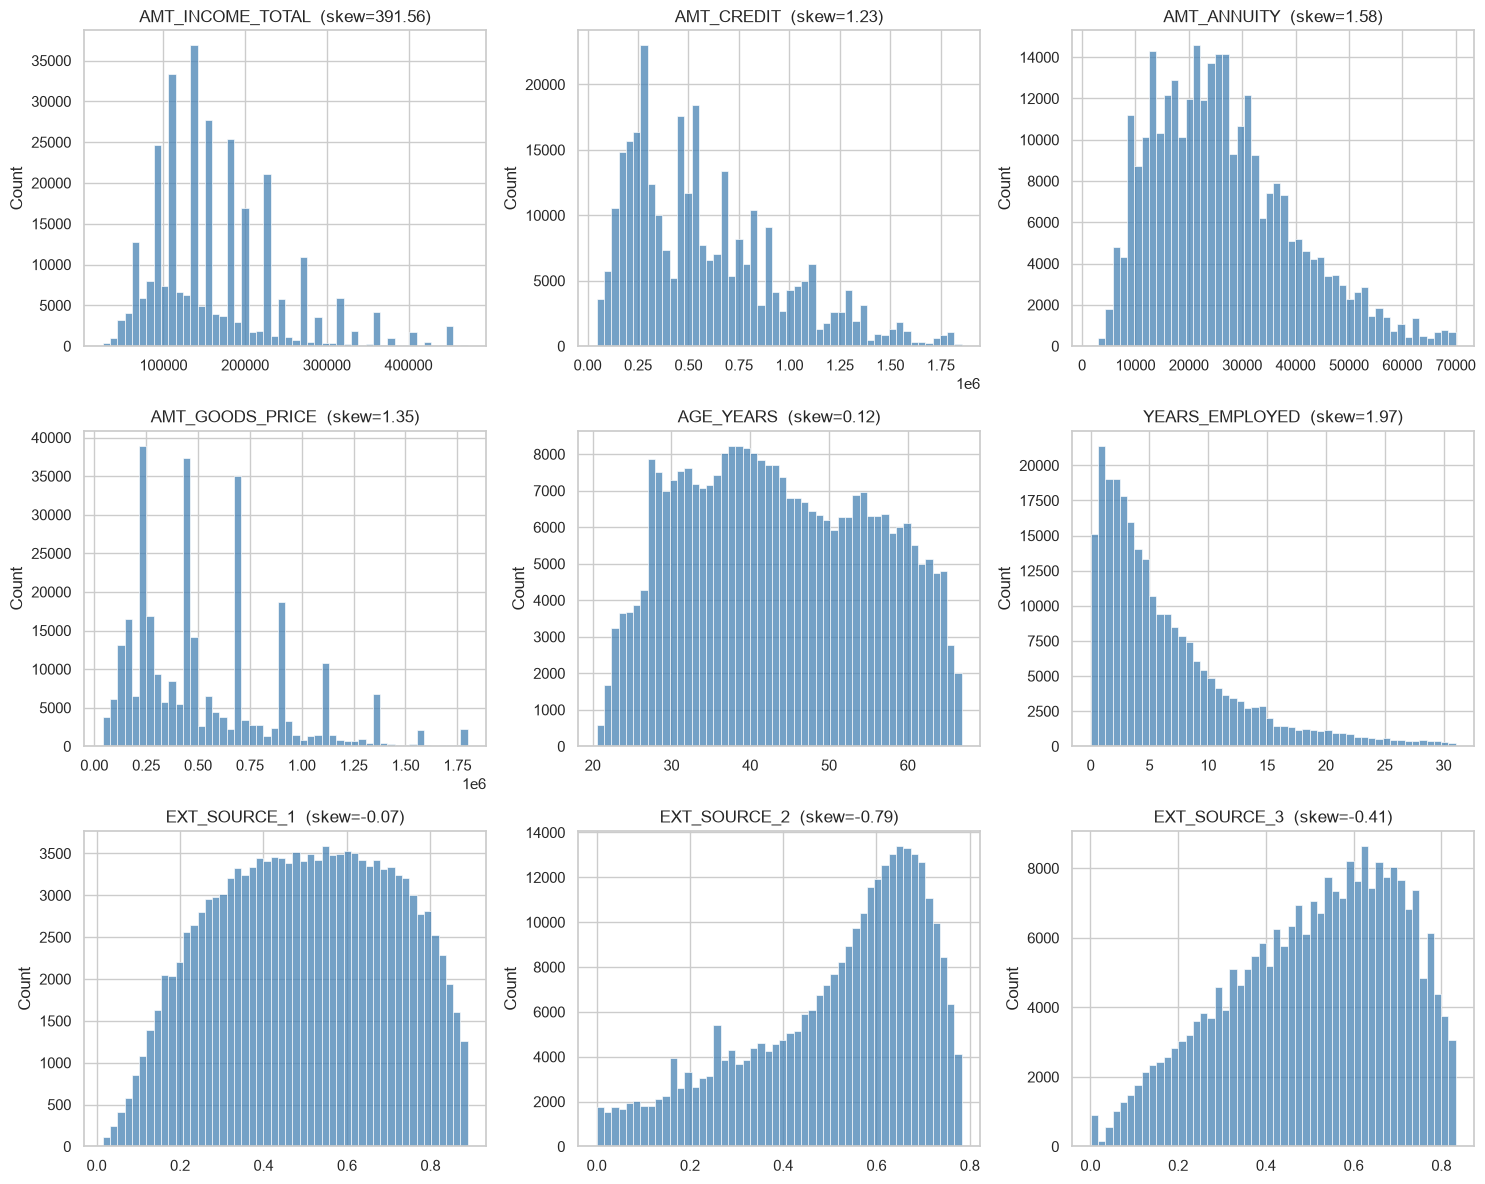

In [13]:
KEY_NUM = [c for c in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
                       "AGE_YEARS", "YEARS_EMPLOYED",
                       "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in d.columns]

fig, axes = grid(len(KEY_NUM))
for ax, c in zip(axes, KEY_NUM):
    s = d[c].dropna()
    s = s[s <= s.quantile(0.99)]          # corta a cauda só para visualizar
    sns.histplot(s, bins=50, ax=ax, color="steelblue")
    ax.set_title(f"{c}  (skew={d[c].skew():.2f})")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [14]:
card = pd.DataFrame({
    "cardinalidade": d[cat_cols].nunique(),
    "pct_nulos": d[cat_cols].isna().mean(),
    "categoria_mais_comum": [d[c].mode().iat[0] if d[c].notna().any() else None for c in cat_cols],
}).sort_values("cardinalidade", ascending=False)
card

,cardinalidade,pct_nulos,categoria_mais_comum
ORGANIZATION_TYPE,57,0.1801,Business Entity Type 3
OCCUPATION_TYPE,18,0.3135,Laborers
NAME_INCOME_TYPE,8,0.0000,Working
NAME_TYPE_SUITE,7,0.0042,Unaccompanied
WALLSMATERIAL_MODE,7,0.5084,Panel
WEEKDAY_APPR_PROCESS_START,7,0.0000,TUESDAY
NAME_FAMILY_STATUS,6,0.0000,Married
NAME_HOUSING_TYPE,6,0.0000,House / apartment
NAME_EDUCATION_TYPE,5,0.0000,Secondary / secondary special
FONDKAPREMONT_MODE,4,0.6839,reg oper account


In [15]:
print("Outliers por IQR (colunas-chave):")
rows = []
for c in KEY_NUM:
    q1, q3 = d[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = ((d[c] < q1 - 1.5 * iqr) | (d[c] > q3 + 1.5 * iqr)).mean()
    rows.append({"coluna": c, "pct_outliers_iqr": out, "max": d[c].max(), "p99": d[c].quantile(0.99)})
pd.DataFrame(rows).set_index("coluna")

Outliers por IQR (colunas-chave):


,pct_outliers_iqr,max,p99
coluna,,,
AMT_INCOME_TOTAL,0.0456,"117,000,000.0000","472,500.0000"
AMT_CREDIT,0.0213,"4,050,000.0000","1,854,000.0000"
AMT_ANNUITY,0.0244,"258,025.5000","70,006.5000"
AMT_GOODS_PRICE,0.0479,"4,050,000.0000","1,800,000.0000"
AGE_YEARS,0.0000,69.0732,66.8556
YEARS_EMPLOYED,0.0493,49.0404,31.0425
EXT_SOURCE_1,0.0000,0.9627,0.8894
EXT_SOURCE_2,0.0000,0.8550,0.7828
EXT_SOURCE_3,0.0000,0.8960,0.8328


## 7. Análise bivariada (variável × target)

**O que observar:** onde a taxa de inadimplência se afasta da média geral (linha vermelha) *com volume suficiente*. Uma taxa alta em 10 linhas não significa nada, por isso mostramos o `n` de cada categoria.

### 7.1 Categóricas

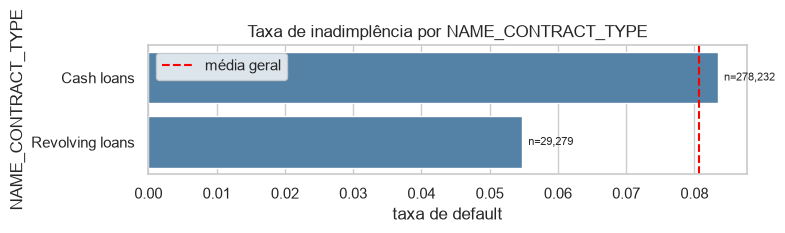

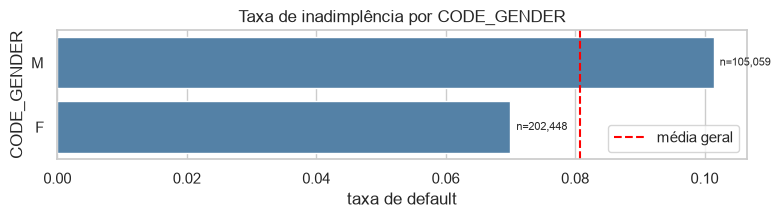

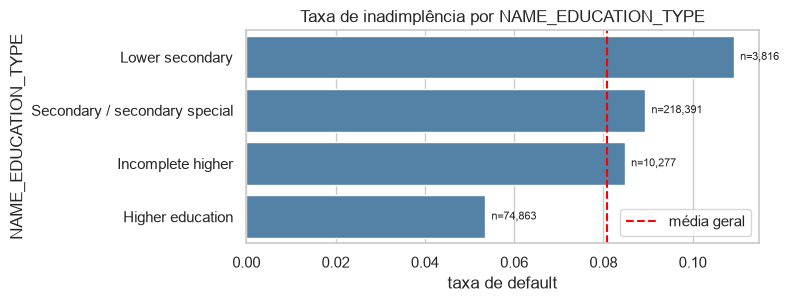

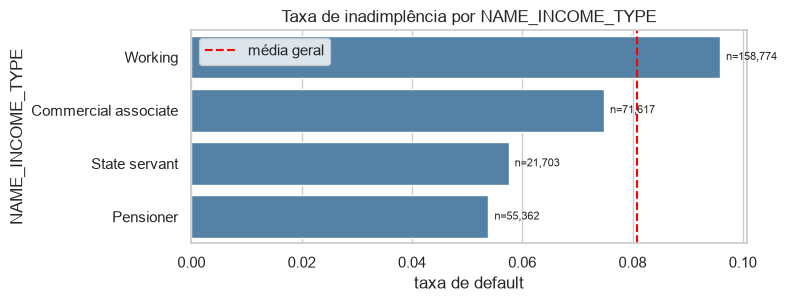

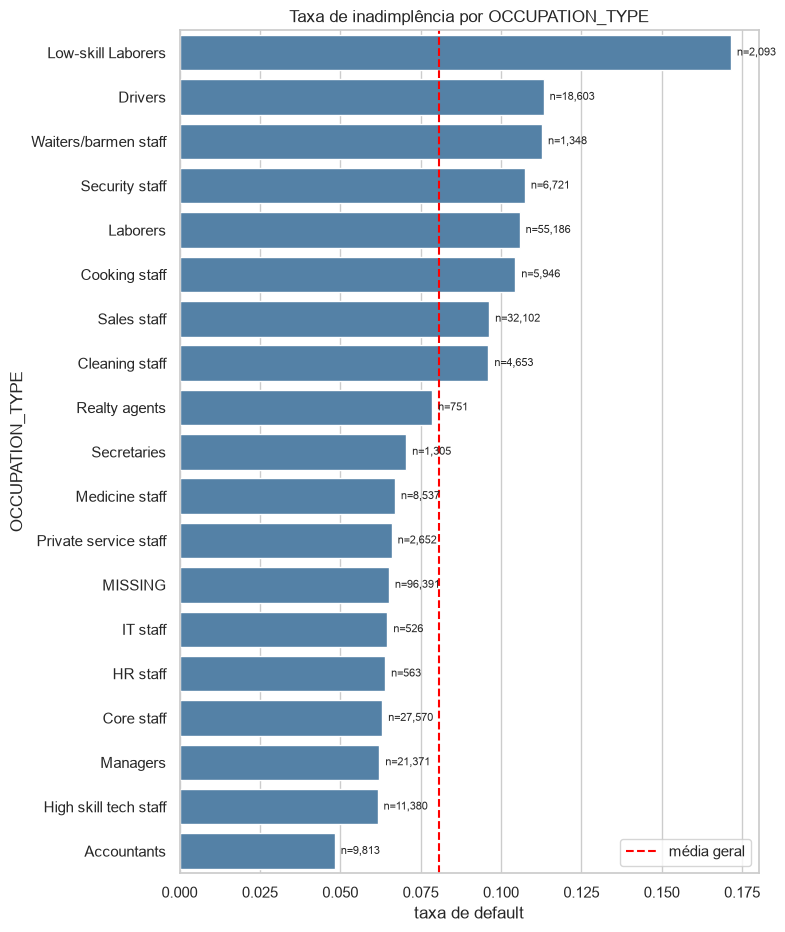

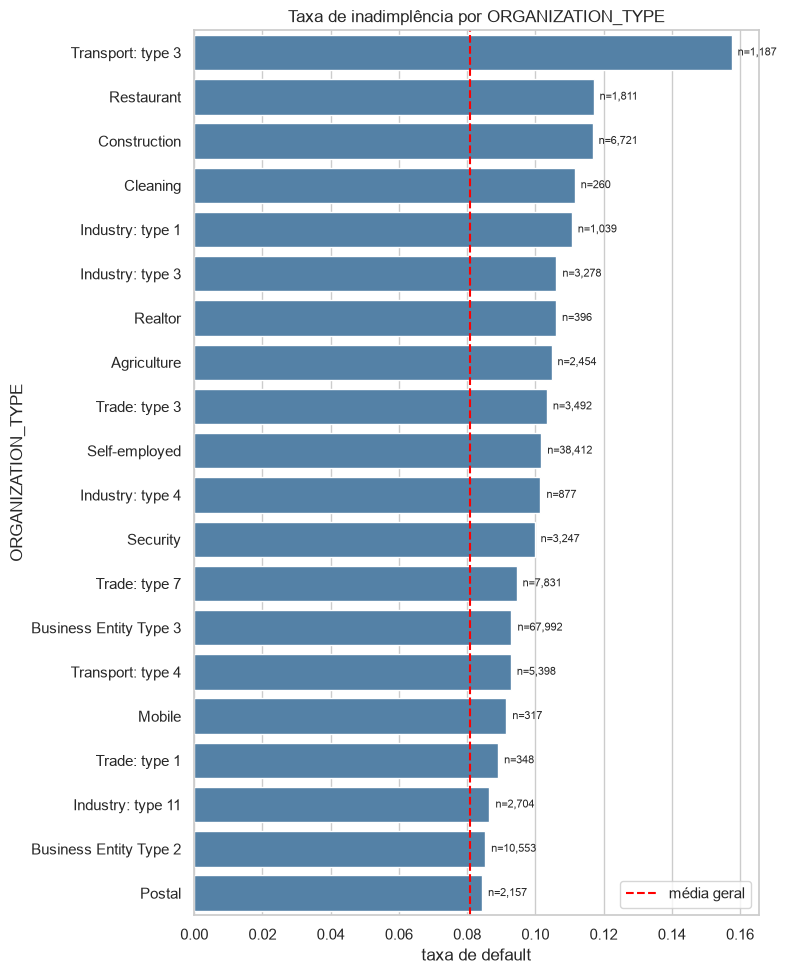

In [16]:
def plot_default_rate_cat(col, min_count=200, top=20):
    t = d.groupby(col, dropna=False)[TARGET].agg(rate="mean", n="count").reset_index()
    t[col] = t[col].fillna("MISSING")
    t = t[t["n"] >= min_count].sort_values("rate", ascending=False).head(top)
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(t) + 1.5))
    sns.barplot(data=t, y=col, x="rate", ax=ax, color="steelblue")
    ax.axvline(d[TARGET].mean(), color="red", ls="--", label="média geral")
    for i, (r, n) in enumerate(zip(t["rate"], t["n"])):
        ax.text(r, i, f"  n={n:,}", va="center", fontsize=8)
    ax.set_title(f"Taxa de inadimplência por {col}")
    ax.set_xlabel("taxa de default")
    ax.legend()
    plt.tight_layout()
    plt.show()


for c in ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_EDUCATION_TYPE",
          "NAME_INCOME_TYPE", "OCCUPATION_TYPE", "ORGANIZATION_TYPE"]:
    if c in d.columns:
        plot_default_rate_cat(c)

### 7.2 Numéricas

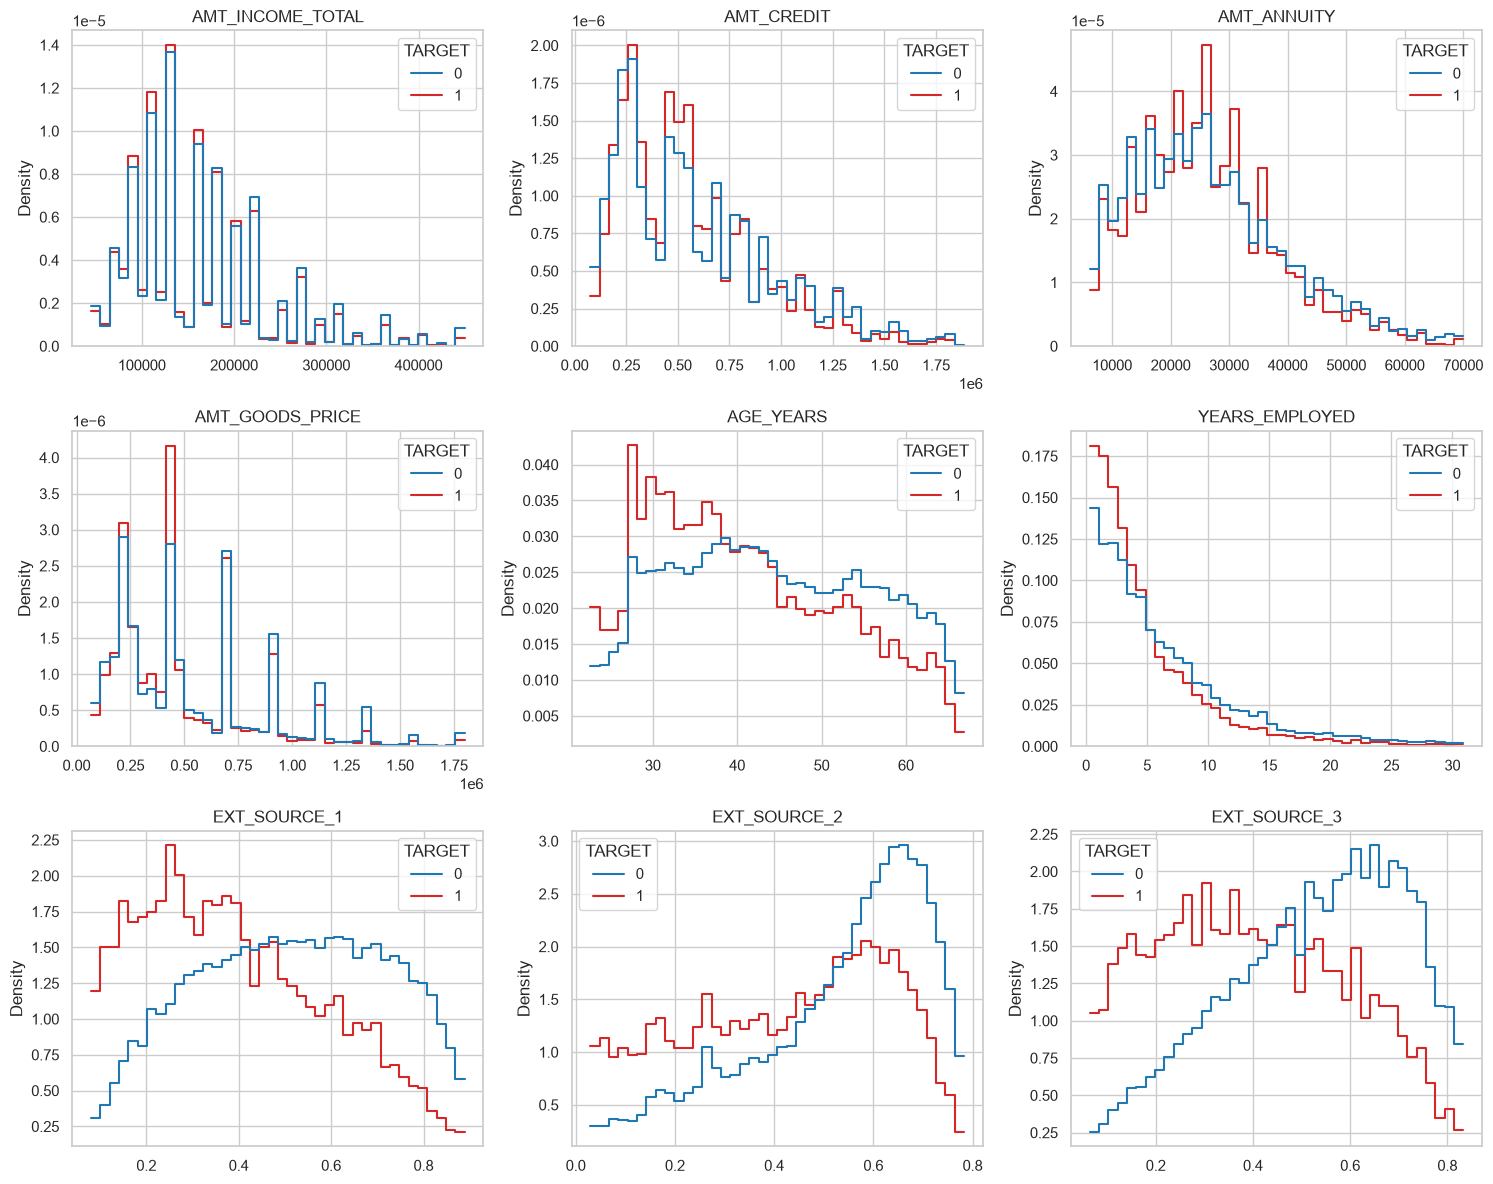

In [17]:
# Distribuição por classe do target (densidade normalizada por classe)
fig, axes = grid(len(KEY_NUM))
for ax, c in zip(axes, KEY_NUM):
    lo, hi = d_s[c].quantile([0.01, 0.99])
    tmp = d_s.loc[d_s[c].between(lo, hi), [c, TARGET]].dropna()
    sns.histplot(data=tmp, x=c, hue=TARGET, stat="density", common_norm=False,
                 element="step", fill=False, bins=40, ax=ax, palette={0: "tab:blue", 1: "tab:red"})
    ax.set_title(c)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

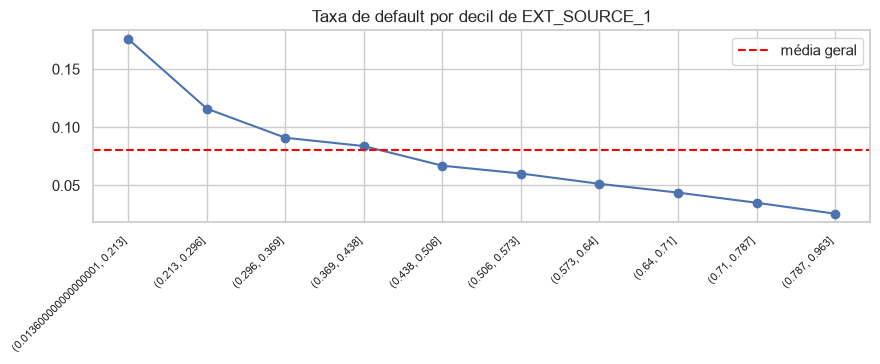

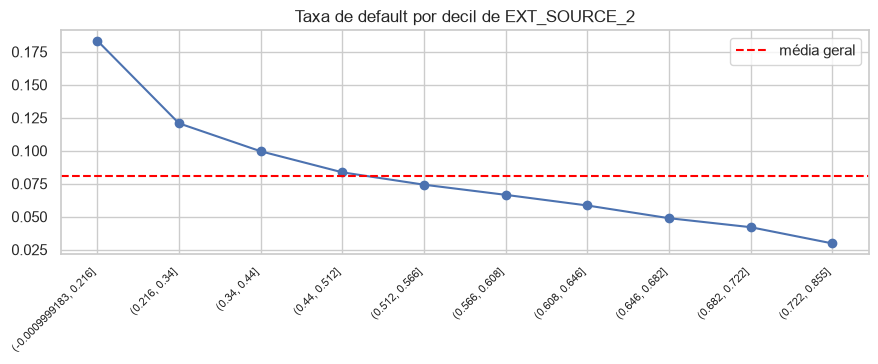

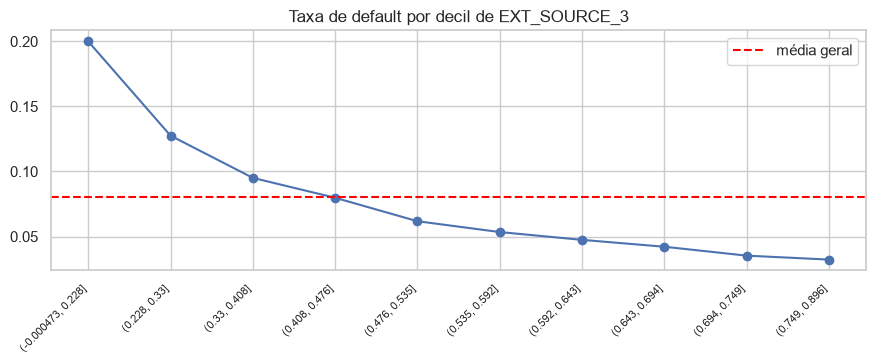

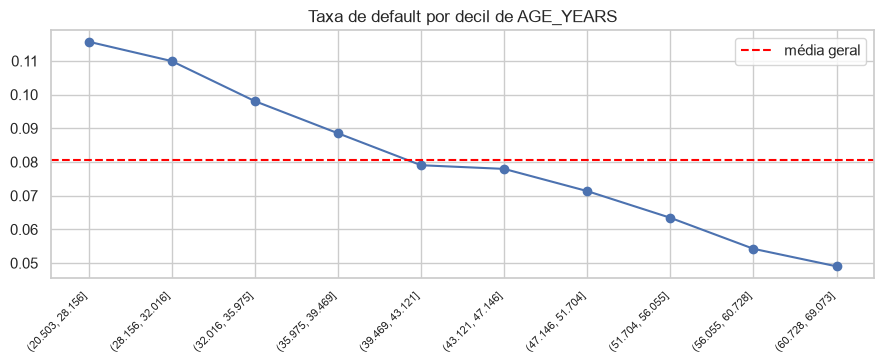

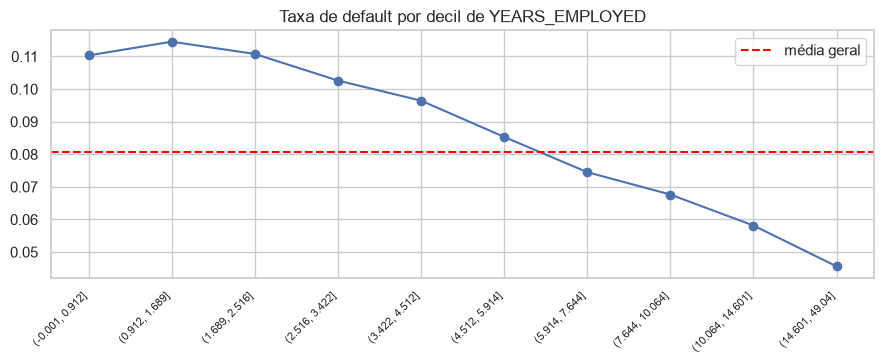

In [18]:
# Taxa de default por faixa (decis): mostra o formato da relação (monotônica? em U?)
def plot_default_rate_bins(col, q=10):
    b = pd.qcut(d[col], q=q, duplicates="drop")
    t = d.groupby(b, observed=True)[TARGET].agg(rate="mean", n="count")
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(range(len(t)), t["rate"].values, marker="o")
    ax.axhline(d[TARGET].mean(), color="red", ls="--", label="média geral")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i) for i in t.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(f"Taxa de default por decil de {col}")
    ax.legend()
    plt.tight_layout()
    plt.show()


for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AGE_YEARS", "YEARS_EMPLOYED"]:
    if c in d.columns:
        plot_default_rate_bins(c)

## 8. Correlações

Duas perguntas diferentes:
1. **Feature × target:** quais variáveis se movem junto com o target? (Spearman captura relações monótonas, não só lineares.)
2. **Feature × feature:** há redundância? Pares com |ρ| > 0,9 carregam quase a mesma informação.

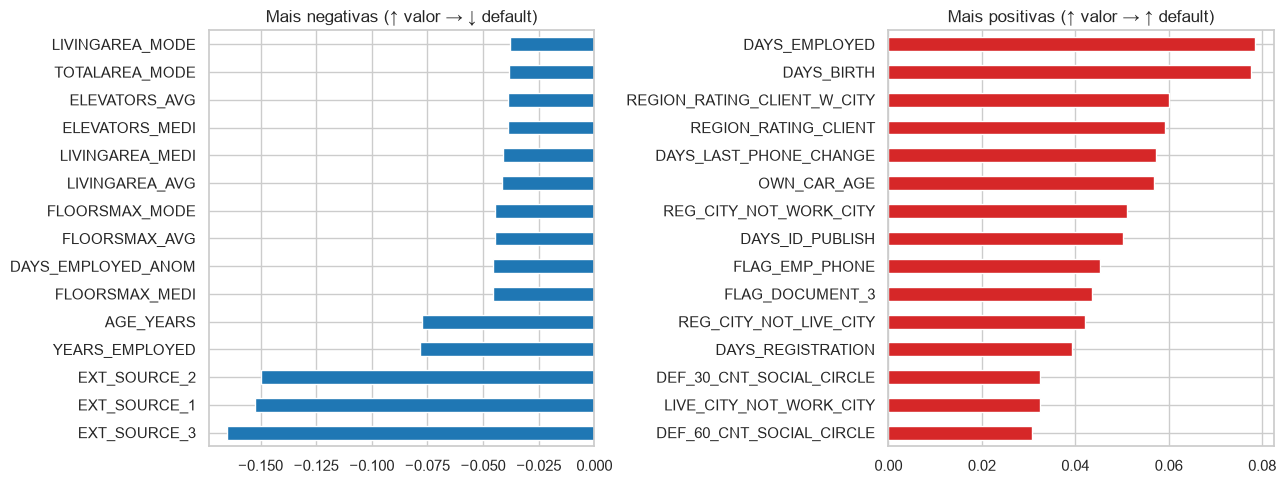

In [19]:
corr_t = (d_s[num_cols + [TARGET]].corr(method="spearman")[TARGET]
          .drop(TARGET).dropna().sort_values())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
corr_t.head(15).plot.barh(ax=axes[0], color="tab:blue", title="Mais negativas (↑ valor → ↓ default)")
corr_t.tail(15).plot.barh(ax=axes[1], color="tab:red", title="Mais positivas (↑ valor → ↑ default)")
plt.tight_layout()
plt.show()

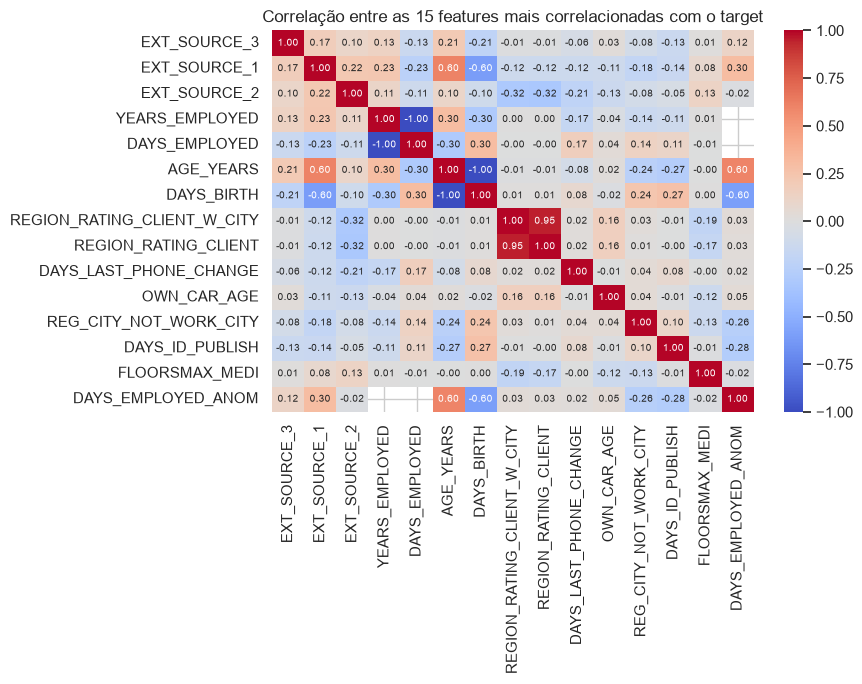

In [20]:
top_abs = corr_t.abs().sort_values(ascending=False).head(15).index.tolist()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(d_s[top_abs].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlação entre as 15 features mais correlacionadas com o target")
plt.tight_layout()
plt.show()

In [21]:
cm = d_s[num_cols].corr().abs()
upper = cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1))
pairs = (upper.stack().rename("abs_corr").reset_index()
         .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
high = pairs[pairs["abs_corr"] > 0.9].sort_values("abs_corr", ascending=False)
print(f"{len(high)} pares com |corr| > 0.9")
high.head(20).reset_index(drop=True)

65 pares com |corr| > 0.9


,feature_a,feature_b,abs_corr
0,DAYS_BIRTH,AGE_YEARS,1.0000
1,DAYS_EMPLOYED,YEARS_EMPLOYED,1.0000
2,FLAG_EMP_PHONE,DAYS_EMPLOYED_ANOM,0.9999
3,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.9984
4,LIVINGAPARTMENTS_AVG,LIVINGAPARTMENTS_MEDI,0.9983
5,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.9982
6,COMMONAREA_AVG,COMMONAREA_MEDI,0.9982
7,NONLIVINGAPARTMENTS_AVG,NONLIVINGAPARTMENTS_MEDI,0.9979
8,ENTRANCES_AVG,ENTRANCES_MEDI,0.9972
9,FLOORSMIN_AVG,FLOORSMIN_MEDI,0.9971


### 8.1 Consistência treino × teste (opcional)

Se `application_test.csv` estiver disponível, compare as distribuições. Uma estatística KS alta indica *drift*: o modelo pode generalizar mal naquela variável.

In [ ]:
test_path = DATA_PATH.parent / "application_test.csv"
if test_path.exists():
    te = pd.read_csv(test_path)
    te["DAYS_EMPLOYED"] = te["DAYS_EMPLOYED"].replace(365243, np.nan)
    cols = [c for c in num_cols if c in te.columns and c not in ("AGE_YEARS", "YEARS_EMPLOYED", "DAYS_EMPLOYED_ANOM")]
    drift = pd.Series({
        c: ks_2samp(d_s[c].dropna(), te[c].dropna()).statistic for c in cols
    }).sort_values(ascending=False)
    print("Top 10 variáveis com maior diferença treino × teste (KS):")
    print(drift.head(10).to_string())
else:
    print("application_test.csv não encontrado; seção ignorada.")

## 9. Poder explicativo: métodos univariados

Cada método olha a variável **sozinha**, sem interações. São ótimos para triagem rápida, mas não enxergam efeitos combinados (isso fica para a seção 10).

| Método | Aplica-se a | Leitura |
|---|---|---|
| **AUC univariada** | numéricas | 0,5 = sem sinal; quanto mais longe de 0,5, melhor |
| **KS** | numéricas | separação máxima entre as distribuições de bons e maus |
| **Information Value (IV)** | todas | <0,02 inútil · 0,02–0,1 fraca · 0,1–0,3 média · 0,3–0,5 forte · >0,5 suspeita de vazamento |
| **Informação mútua** | numéricas | captura relações não lineares |
| **Cramér's V** | categóricas | associação (0 a 1) com o target |

> Nos métodos que exigem valores completos preenchemos nulos com a mediana; a informação *do nulo* em si é capturada pelo IV (nulo vira uma faixa própria).

In [22]:
def uni_auc(s, y):
    s = s.fillna(s.median())
    a = roc_auc_score(y, s)
    return max(a, 1 - a)          # direção não importa para "poder de separação"


def ks_stat(s, y):
    a, b = s[y == 1].dropna(), s[y == 0].dropna()
    return ks_2samp(a, b).statistic


auc_num = pd.Series({c: uni_auc(d_s[c], d_s[TARGET]) for c in num_cols}, name="auc_uni")
ks_num = pd.Series({c: ks_stat(d_s[c], d_s[TARGET]) for c in num_cols}, name="ks")

pd.concat([auc_num, ks_num], axis=1).sort_values("auc_uni", ascending=False).head(20)

,auc_uni,ks
EXT_SOURCE_2,0.6593,0.2273
EXT_SOURCE_3,0.6489,0.2670
EXT_SOURCE_1,0.5826,0.2506
DAYS_BIRTH,0.5825,0.1224
AGE_YEARS,0.5825,0.1224
YEARS_EMPLOYED,0.5779,0.1307
DAYS_EMPLOYED,0.5779,0.1307
DAYS_LAST_PHONE_CHANGE,0.5609,0.1042
DAYS_ID_PUBLISH,0.5535,0.0839
REGION_RATING_CLIENT_W_CITY,0.5486,0.0615


In [23]:
def information_value(x, y, bins=10, eps=0.5):
    """IV com suavização de Laplace. Numéricas contínuas viram quantis; nulos viram faixa própria."""
    if pd.api.types.is_numeric_dtype(x) and x.nunique() > bins:
        x = pd.qcut(x, q=bins, duplicates="drop")
    x = x.astype("object").where(x.notna(), "MISSING").astype(str)

    tab = pd.crosstab(x, y)
    for k in (0, 1):
        if k not in tab.columns:
            tab[k] = 0
    good, bad = tab[0], tab[1]
    pct_good = (good + eps) / (good.sum() + eps * len(tab))
    pct_bad = (bad + eps) / (bad.sum() + eps * len(tab))
    woe = np.log(pct_good / pct_bad)
    return float(((pct_good - pct_bad) * woe).sum())


iv_s = pd.Series({c: information_value(d[c], d[TARGET]) for c in num_cols + cat_cols}, name="iv")
iv_s = iv_s.sort_values(ascending=False)

faixas = pd.cut(iv_s, [-1, 0.02, 0.1, 0.3, 0.5, np.inf],
                labels=["inútil", "fraca", "média", "forte", "suspeita"])
print(faixas.value_counts().reindex(["inútil", "fraca", "média", "forte", "suspeita"]).to_string())
iv_s.head(20).to_frame()

iv
inútil      65
fraca       53
média        3
forte        2
suspeita     0


,iv
EXT_SOURCE_3,0.3293
EXT_SOURCE_2,0.3063
EXT_SOURCE_1,0.1508
DAYS_EMPLOYED,0.1111
YEARS_EMPLOYED,0.1111
AMT_GOODS_PRICE,0.0919
DAYS_BIRTH,0.0842
AGE_YEARS,0.0841
OCCUPATION_TYPE,0.0828
ORGANIZATION_TYPE,0.0731


In [24]:
d_mi = d_s.sample(min(len(d_s), 30_000), random_state=SEED)
X_mi = d_mi[num_cols].apply(lambda s: s.fillna(s.median())).fillna(0)
mi_s = pd.Series(mutual_info_classif(X_mi, d_mi[TARGET], random_state=SEED),
                 index=num_cols, name="mi")
mi_s.sort_values(ascending=False).head(20).to_frame()

,mi
EXT_SOURCE_2,0.0146
EXT_SOURCE_3,0.0137
AMT_ANNUITY,0.0084
DAYS_EMPLOYED,0.0071
FLOORSMAX_MEDI,0.0060
FLAG_EMP_PHONE,0.0060
FLOORSMIN_MEDI,0.0059
EXT_SOURCE_1,0.0059
FLOORSMIN_MODE,0.0057
FLAG_MOBIL,0.0055


In [25]:
def cramers_v(x, y):
    ct = pd.crosstab(x.fillna("MISSING"), y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    return float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))


cv_s = pd.Series({c: cramers_v(d[c], d[TARGET]) for c in cat_cols}, name="cramers_v")
cv_s.sort_values(ascending=False).to_frame()

,cramers_v
OCCUPATION_TYPE,0.0801
ORGANIZATION_TYPE,0.0723
NAME_INCOME_TYPE,0.0638
NAME_EDUCATION_TYPE,0.0576
CODE_GENDER,0.0547
WALLSMATERIAL_MODE,0.0441
EMERGENCYSTATE_MODE,0.0422
HOUSETYPE_MODE,0.0407
NAME_FAMILY_STATUS,0.0405
NAME_HOUSING_TYPE,0.0370


## 10. Poder explicativo: métodos baseados em modelo

Aqui o modelo enxerga **interações** e **não linearidades**. Usamos LightGBM (trata nulos e categóricas nativamente) com CV estratificado e extraímos:

- **Importância por *gain*:** rápida, mas enviesada a variáveis de alta cardinalidade.
- **Permutation importance:** embaralha uma variável e mede a queda de AUC em dados de validação. Mais confiável.
- **SHAP:** contribuição de cada variável por previsão, com a **direção** do efeito.

> O AUC desta seção é o seu **baseline** de referência. Todo feature engineering posterior deve ser comparado com ele.

In [27]:
if RUN_MODEL:
    import lightgbm as lgb

    X = d.drop(columns=[TARGET, ID]).copy()
    for c in cat_cols:
        X[c] = X[c].astype("category")
    y = d[TARGET]

    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    oof = np.zeros(len(X))
    gains = pd.DataFrame(index=X.columns)

    for i, (tr, va) in enumerate(skf.split(X, y)):
        model = lgb.LGBMClassifier(
            n_estimators=2000, learning_rate=0.05, num_leaves=31,
            colsample_bytree=0.5, subsample=0.8, subsample_freq=1, reg_lambda=1.0,
            importance_type="gain", random_state=SEED, n_jobs=-1, verbose=-1,
        )
        model.fit(X.iloc[tr], y.iloc[tr],
                  eval_set=[(X.iloc[va], y.iloc[va])], eval_metric="auc",
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[va] = model.predict_proba(X.iloc[va])[:, 1]
        gains[f"fold{i}"] = model.feature_importances_
        print(f"fold {i}: AUC = {roc_auc_score(y.iloc[va], oof[va]):.4f} "
              f"({model.best_iteration_} árvores)")

    print(f"\nAUC out-of-fold (baseline): {roc_auc_score(y, oof):.4f}")
    gain_s = gains.mean(axis=1).rename("gain")
    last_va = va
    gain_s.sort_values(ascending=False).head(20).to_frame()

fold 0: AUC = 0.7561 (246 árvores)
fold 1: AUC = 0.7666 (321 árvores)
fold 2: AUC = 0.7583 (479 árvores)
fold 3: AUC = 0.7626 (506 árvores)
fold 4: AUC = 0.7562 (462 árvores)

AUC out-of-fold (baseline): 0.7599


In [28]:
if RUN_MODEL:
    Xv = X.iloc[last_va].sample(min(20_000, len(last_va)), random_state=SEED)
    yv = y.loc[Xv.index]
    base = roc_auc_score(yv, model.predict_proba(Xv)[:, 1])

    pi = permutation_importance(model, Xv, yv, scoring="roc_auc",
                                n_repeats=3, random_state=SEED, n_jobs=1)
    perm_s = pd.Series(pi.importances_mean, index=Xv.columns, name="perm")
    print(f"AUC da validação (amostra): {base:.4f}  |  valores = queda de AUC ao embaralhar")
    perm_s.sort_values(ascending=False).head(20).to_frame()

AUC da validação (amostra): 0.7531  |  valores = queda de AUC ao embaralhar


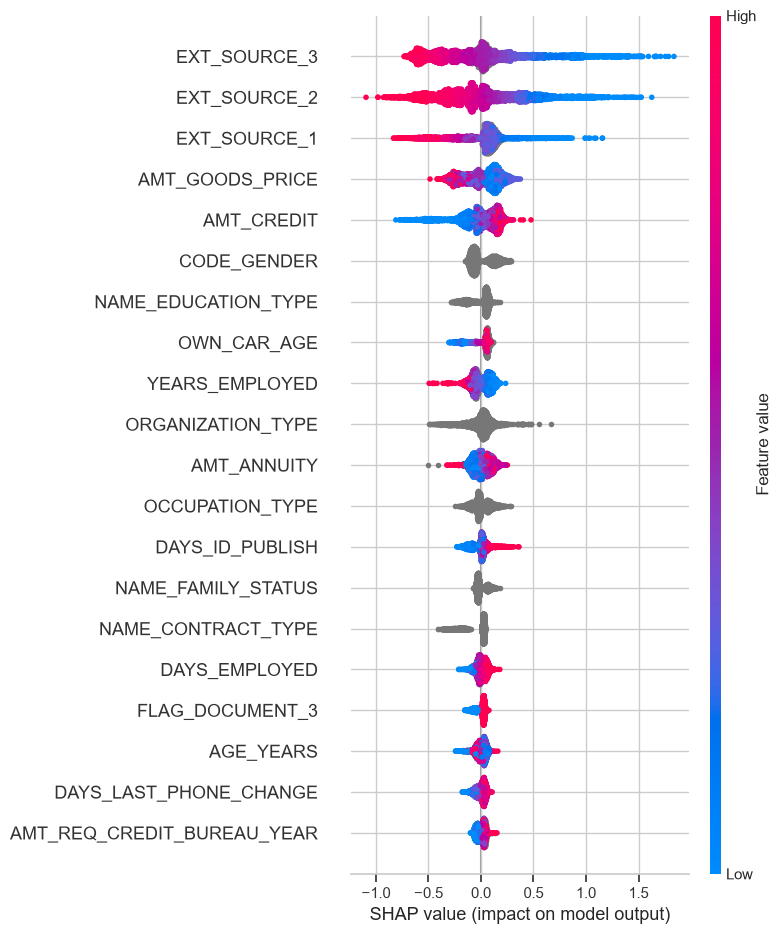

In [30]:
if RUN_MODEL:
    try:
        import shap

        Xs = Xv.sample(min(5_000, len(Xv)), random_state=SEED)
        sv = shap.TreeExplainer(model).shap_values(Xs)
        if isinstance(sv, list):          # versões antigas retornam [classe0, classe1]
            sv = sv[1]
        shap.summary_plot(sv, Xs, max_display=20)
    except ImportError:
        print("Instale o SHAP para ver este gráfico:  pip install shap")

## 11. Ranking consolidado

Combinamos todos os métodos em uma tabela e calculamos o **rank médio** (menor = mais importante).

**Como ler:**
- Forte em *todos* os métodos → candidata sólida.
- Forte no modelo mas fraca nos univariados → efeito de **interação**; vale investigar.
- Forte nos univariados mas fraca no modelo → provavelmente **redundante** com outra variável.
- IV > 0,5 ou AUC univariada > 0,8 → desconfie de **vazamento**.

> Colunas categóricas só têm IV, Cramér's V e (se o modelo rodou) gain/perm, então o rank médio delas é calculado sobre menos métodos.

In [31]:
parts = [auc_num, ks_num, mi_s, iv_s, cv_s]
if RUN_MODEL:
    parts += [gain_s, perm_s]

summary = pd.concat(parts, axis=1)
summary["rank_medio"] = summary.rank(ascending=False).mean(axis=1)
summary = summary.sort_values("rank_medio")
summary.head(25)

,auc_uni,ks,mi,iv,cramers_v,gain,perm,rank_medio
EXT_SOURCE_3,0.6489,0.2670,0.0137,0.3293,NaN,"48,769.8880",0.0571,1.3333
EXT_SOURCE_2,0.6593,0.2273,0.0146,0.3063,NaN,"40,807.1967",0.0427,1.8333
EXT_SOURCE_1,0.5826,0.2506,0.0059,0.1508,NaN,"17,710.4783",0.0180,3.8333
ORGANIZATION_TYPE,NaN,NaN,NaN,0.0731,0.0723,"14,874.1199",0.0036,6.0000
OCCUPATION_TYPE,NaN,NaN,NaN,0.0828,0.0801,"6,227.2374",0.0020,8.0000
YEARS_EMPLOYED,0.5779,0.1307,0.0044,0.1111,NaN,"6,698.2739",0.0032,8.9167
DAYS_EMPLOYED,0.5779,0.1307,0.0071,0.1111,NaN,"5,198.1537",0.0007,8.9167
NAME_EDUCATION_TYPE,NaN,NaN,NaN,0.0507,0.0576,"3,596.8961",0.0029,11.0000
AGE_YEARS,0.5825,0.1224,0.0038,0.0841,NaN,"5,292.9617",0.0015,11.6667
CODE_GENDER,NaN,NaN,NaN,0.0386,0.0547,"2,674.5365",0.0042,11.7500


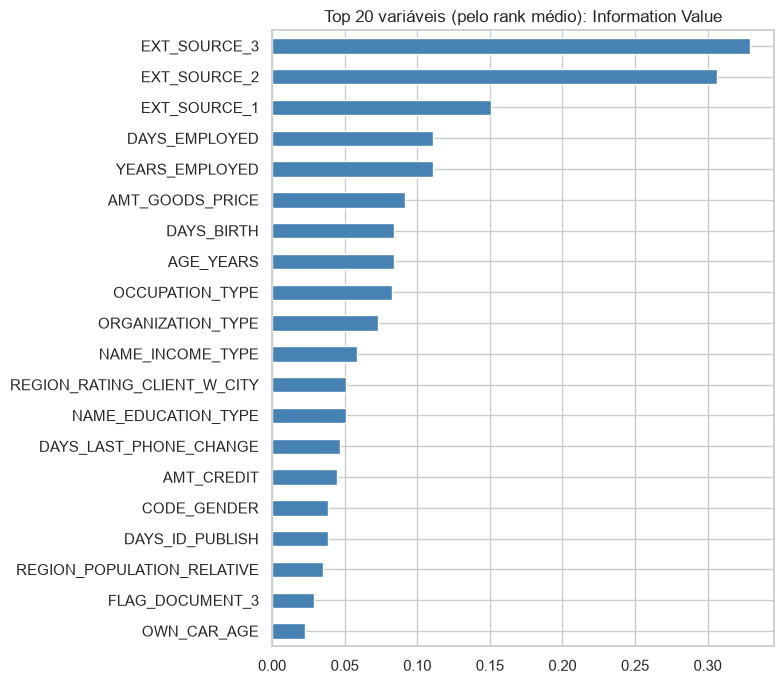

In [32]:
top = summary.head(20).index
fig, ax = plt.subplots(figsize=(8, 7))
(summary.loc[top, "iv"].sort_values().plot.barh(ax=ax, color="steelblue"))
ax.set_title("Top 20 variáveis (pelo rank médio): Information Value")
plt.tight_layout()
plt.show()

## 12. Teste rápido de features engenheiradas

Razões entre valores monetários e combinações dos scores externos costumam superar as colunas originais. Verificamos o poder de cada uma com as mesmas métricas univariadas.

In [33]:
eng = pd.DataFrame(index=d.index)
eng["CREDIT_INCOME_RATIO"] = d["AMT_CREDIT"] / d["AMT_INCOME_TOTAL"]
eng["ANNUITY_INCOME_RATIO"] = d["AMT_ANNUITY"] / d["AMT_INCOME_TOTAL"]
eng["CREDIT_TERM"] = d["AMT_ANNUITY"] / d["AMT_CREDIT"]            # ~ 1 / prazo
eng["GOODS_CREDIT_RATIO"] = d["AMT_GOODS_PRICE"] / d["AMT_CREDIT"]
eng["EMPLOYED_AGE_RATIO"] = d["DAYS_EMPLOYED"] / d["DAYS_BIRTH"]
eng["INCOME_PER_PERSON"] = d["AMT_INCOME_TOTAL"] / d["CNT_FAM_MEMBERS"]

ext = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in d.columns]
if ext:
    eng["EXT_SOURCE_MEAN"] = d[ext].mean(axis=1)
    eng["EXT_SOURCE_PROD"] = d[ext].prod(axis=1, min_count=len(ext))

eng = eng.replace([np.inf, -np.inf], np.nan)
eng_s = eng.loc[d_s.index]

res = pd.DataFrame({
    "auc_uni": {c: uni_auc(eng_s[c], d_s[TARGET]) for c in eng.columns},
    "iv": {c: information_value(eng[c], d[TARGET]) for c in eng.columns},
}).sort_values("auc_uni", ascending=False)

ref = summary.loc[[c for c in ext if c in summary.index], ["auc_uni", "iv"]]
pd.concat([res.assign(tipo="engenheirada"), ref.assign(tipo="original")]).sort_values("auc_uni", ascending=False)

,auc_uni,iv,tipo
EXT_SOURCE_MEAN,0.7184,0.6081,engenheirada
EXT_SOURCE_2,0.6593,0.3063,original
EXT_SOURCE_3,0.6489,0.3293,original
EXT_SOURCE_PROD,0.5971,0.2696,engenheirada
EXT_SOURCE_1,0.5826,0.1508,original
GOODS_CREDIT_RATIO,0.5727,0.0720,engenheirada
EMPLOYED_AGE_RATIO,0.5654,0.0903,engenheirada
CREDIT_TERM,0.5257,0.0935,engenheirada
INCOME_PER_PERSON,0.5182,0.0040,engenheirada
ANNUITY_INCOME_RATIO,0.5179,0.0059,engenheirada


## 13. Conclusões e próximos passos

Preencha após rodar o notebook com os seus dados.

**Qualidade dos dados**
- [ ] Colunas com mais de X% de nulos e como serão tratadas (remover, imputar, indicador de ausência)
- [ ] Anomalias encontradas (`DAYS_EMPLOYED`, `XNA`, outliers) e a decisão para cada uma

**Variáveis mais informativas**
- [ ] Top 10 pelo rank consolidado
- [ ] Variáveis suspeitas de vazamento (IV > 0,5)
- [ ] Grupos de variáveis redundantes (pares com |ρ| > 0,9) e qual manter

**Baseline**
- [ ] AUC out-of-fold: ______

**Próximos passos**
1. Fixar uma função de limpeza em `src/data/` com as correções da seção 5.
2. Agregar `bureau`, `previous_application`, `installments_payments`, etc. por `SK_ID_CURR` (feature engineering).
3. Repetir a seção 9–11 nas novas features e comparar o AUC com o baseline.
4. Testar tuning, ensembling e calibração das probabilidades.